In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    LogisticRegression
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = {
    "Study_Hours": [
        2, 3, 4, 5, 6, 7, 8, 9,
        2, 4, 5, 6, 7, 8, 9, 10,
        3, 5, 6, 7, 8, 9
    ],

    "Attendance": [
        60, 65, 70, 75, 80, 85, 90, 95,
        62, 72, 77, 82, 87, 91, 94, 97,
        68, 76, 84, 88, 92, 96
    ],

    "Assignment_Score": [
        55, 60, 65, 68, 72, 78, 84, 90,
        58, 66, 71, 75, 80, 86, 91, 95,
        62, 70, 76, 82, 88, 93
    ],

    "Final_Marks": [
        50, 55, 62, 68, 73, 80, 86, 92,
        52, 63, 69, 74, 82, 88, 93, 97,
        58, 68, 75, 81, 89, 95
    ]
}

df = pd.DataFrame(data)

print(df.head())
print("\nDataset shape:", df.shape)

   Study_Hours  Attendance  Assignment_Score  Final_Marks
0            2          60                55           50
1            3          65                60           55
2            4          70                65           62
3            5          75                68           68
4            6          80                72           73

Dataset shape: (22, 4)


In [3]:
X = df[
    ["Study_Hours", "Attendance", "Assignment_Score"]
]

y = df["Final_Marks"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Study_Hours  Attendance  Assignment_Score
0            2          60                55
1            3          65                60
2            4          70                65
3            5          75                68
4            6          80                72

Target:
0    50
1    55
2    62
3    68
4    73
Name: Final_Marks, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 17
Testing samples: 5


In [5]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression Predictions:")
print(linear_predictions)

Linear Regression Predictions:
[50.22262305 87.27809096 51.9326128  56.3000524  98.65400074]


In [6]:
linear_mse = mean_squared_error(
    y_test,
    linear_predictions
)

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

print("Linear Regression Results")
print("-------------------------")
print("MSE:", linear_mse)
print("MAE:", linear_mae)
print("R² Score:", linear_r2)

Linear Regression Results
-------------------------
MSE: 1.0002218808335746
MAE: 0.7931944860308164
R² Score: 0.9974858689904645


In [7]:
polynomial_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

polynomial_model.fit(X_train, y_train)

polynomial_predictions = polynomial_model.predict(X_test)

print("Polynomial Regression Predictions:")
print(polynomial_predictions)

Polynomial Regression Predictions:
[50.83947904 87.11665769 53.98449723 56.46435644 96.95713222]


In [8]:
poly_mse = mean_squared_error(
    y_test,
    polynomial_predictions
)

poly_mae = mean_absolute_error(
    y_test,
    polynomial_predictions
)

poly_r2 = r2_score(
    y_test,
    polynomial_predictions
)

print("Polynomial Regression Results")
print("-----------------------------")
print("MSE:", poly_mse)
print("MAE:", poly_mae)
print("R² Score:", poly_r2)

Polynomial Regression Results
-----------------------------
MSE: 1.5138850768353767
MAE: 1.042908560193871
R² Score: 0.9961947388979605


In [9]:
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

ridge_model.fit(X_train, y_train)

ridge_predictions = ridge_model.predict(X_test)

print("Ridge Regression Predictions:")
print(ridge_predictions)

Ridge Regression Predictions:
[50.02097973 87.06895565 51.96766209 56.06668315 97.2628552 ]


In [10]:
ridge_mse = mean_squared_error(
    y_test,
    ridge_predictions
)

ridge_mae = mean_absolute_error(
    y_test,
    ridge_predictions
)

ridge_r2 = r2_score(
    y_test,
    ridge_predictions
)

print("Ridge Regression Results")
print("------------------------")
print("MSE:", ridge_mse)
print("MAE:", ridge_mae)
print("R² Score:", ridge_r2)

Ridge Regression Results
------------------------
MSE: 0.4150470503254039
MAE: 0.4627800666224175
R² Score: 0.9989567488178026


In [11]:
lasso_model = make_pipeline(
    StandardScaler(),
    Lasso(alpha=0.1)
)

lasso_model.fit(X_train, y_train)

lasso_predictions = lasso_model.predict(X_test)

print("Lasso Regression Predictions:")
print(lasso_predictions)

Lasso Regression Predictions:
[50.46539291 87.18525281 52.16466673 56.48752837 98.45687389]


In [12]:
lasso_mse = mean_squared_error(
    y_test,
    lasso_predictions
)

lasso_mae = mean_absolute_error(
    y_test,
    lasso_predictions
)

lasso_r2 = r2_score(
    y_test,
    lasso_predictions
)

print("Lasso Regression Results")
print("------------------------")
print("MSE:", lasso_mse)
print("MAE:", lasso_mae)
print("R² Score:", lasso_r2)

Lasso Regression Results
------------------------
MSE: 1.0485481706473974
MAE: 0.8778418173378284
R² Score: 0.9973643973189036


In [13]:
regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],

    "MAE": [
        linear_mae,
        poly_mae,
        ridge_mae,
        lasso_mae
    ],

    "MSE": [
        linear_mse,
        poly_mse,
        ridge_mse,
        lasso_mse
    ],

    "R2 Score": [
        linear_r2,
        poly_r2,
        ridge_r2,
        lasso_r2
    ]
})

print(regression_results)

                   Model       MAE       MSE  R2 Score
0      Linear Regression  0.793194  1.000222  0.997486
1  Polynomial Regression  1.042909  1.513885  0.996195
2       Ridge Regression  0.462780  0.415047  0.998957
3       Lasso Regression  0.877842  1.048548  0.997364


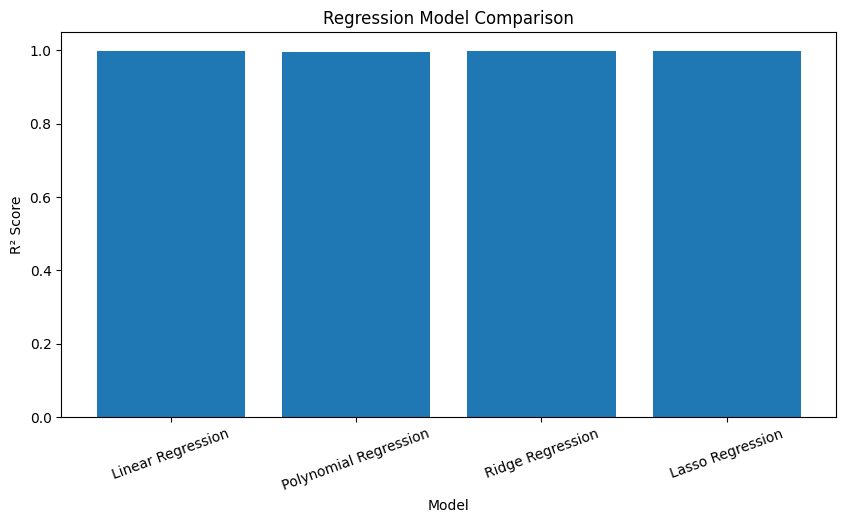

In [14]:
plt.figure(figsize=(10, 5))

plt.bar(
    regression_results["Model"],
    regression_results["R2 Score"]
)

plt.title("Regression Model Comparison")
plt.xlabel("Model")
plt.ylabel("R² Score")

plt.xticks(rotation=20)
plt.show()

In [15]:
classification_df = df.copy()

classification_df["Result"] = np.where(
    classification_df["Final_Marks"] >= 60,
    1,
    0
)

print(classification_df)

    Study_Hours  Attendance  Assignment_Score  Final_Marks  Result
0             2          60                55           50       0
1             3          65                60           55       0
2             4          70                65           62       1
3             5          75                68           68       1
4             6          80                72           73       1
5             7          85                78           80       1
6             8          90                84           86       1
7             9          95                90           92       1
8             2          62                58           52       0
9             4          72                66           63       1
10            5          77                71           69       1
11            6          82                75           74       1
12            7          87                80           82       1
13            8          91                86           88    

In [16]:
X_class = classification_df[
    ["Study_Hours", "Attendance", "Assignment_Score"]
]

y_class = classification_df["Result"]

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print("Training samples:", len(X_train_class))
print("Testing samples:", len(X_test_class))

Training samples: 17
Testing samples: 5


In [17]:
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)

logistic_model.fit(
    X_train_class,
    y_train_class
)

logistic_predictions = logistic_model.predict(
    X_test_class
)

print("Logistic Regression Predictions:")
print(logistic_predictions)

Logistic Regression Predictions:
[0 1 1 1 1]


In [18]:
logistic_accuracy = accuracy_score(
    y_test_class,
    logistic_predictions
)

print("Logistic Regression Accuracy:")
print(logistic_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test_class,
        logistic_predictions,
        zero_division=0
    )
)

Logistic Regression Accuracy:
1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         4

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



In [19]:
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)

knn_model.fit(
    X_train_class,
    y_train_class
)

knn_predictions = knn_model.predict(
    X_test_class
)

print("KNN Predictions:")
print(knn_predictions)

KNN Predictions:
[0 1 1 1 1]


In [20]:
knn_accuracy = accuracy_score(
    y_test_class,
    knn_predictions
)

print("KNN Accuracy:")
print(knn_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test_class,
        knn_predictions,
        zero_division=0
    )
)

KNN Accuracy:
1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         4

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



In [21]:
classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN"
    ],

    "Accuracy": [
        logistic_accuracy,
        knn_accuracy
    ]
})

print(classification_results)

                 Model  Accuracy
0  Logistic Regression       1.0
1                  KNN       1.0


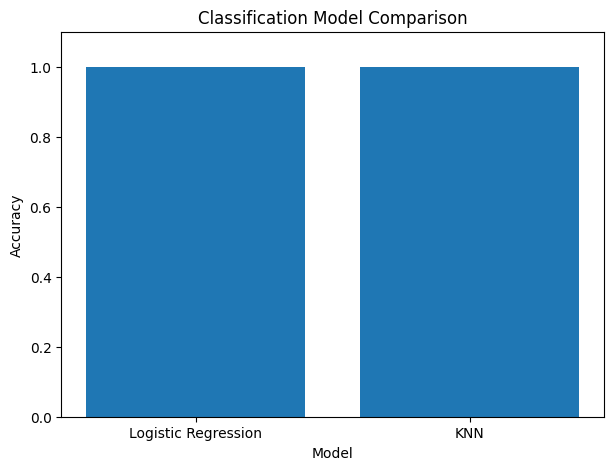

In [22]:
plt.figure(figsize=(7, 5))

plt.bar(
    classification_results["Model"],
    classification_results["Accuracy"]
)

plt.title("Classification Model Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")

plt.ylim(0, 1.1)
plt.show()

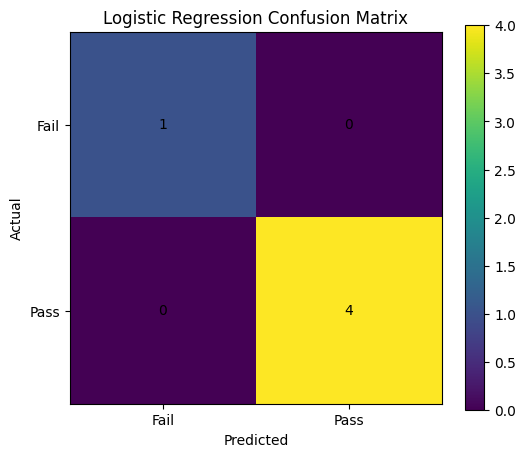

In [23]:
cm = confusion_matrix(
    y_test_class,
    logistic_predictions
)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Fail", "Pass"])
plt.yticks([0, 1], ["Fail", "Pass"])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()

In [24]:
new_student = pd.DataFrame({
    "Study_Hours": [7],
    "Attendance": [90],
    "Assignment_Score": [85]
})

# Predict marks
predicted_marks = linear_model.predict(new_student)

# Predict pass/fail
predicted_result = logistic_model.predict(new_student)

print("New Student")
print("----------------")
print("Study Hours:", new_student["Study_Hours"].iloc[0])
print("Attendance:", new_student["Attendance"].iloc[0])
print("Assignment Score:", new_student["Assignment_Score"].iloc[0])

print("\nPredicted Marks:", round(predicted_marks[0], 2))

if predicted_result[0] == 1:
    print("Predicted Result: PASS")
else:
    print("Predicted Result: FAIL")

New Student
----------------
Study Hours: 7
Attendance: 90
Assignment Score: 85

Predicted Marks: 83.56
Predicted Result: PASS


In [25]:
print("==========================================")
print("     HACK-O-WEEK ML MODELS")
print("==========================================")

print("\nREGRESSION")
print("✓ Linear Regression")
print("✓ Polynomial Regression")
print("✓ Ridge Regression")
print("✓ Lasso Regression")

print("\nCLASSIFICATION")
print("✓ Logistic Regression")
print("✓ K-Nearest Neighbors (KNN)")

print("\nAPPLICATION")
print("✓ Student Marks Prediction")
print("✓ Student Pass/Fail Classification")

print("\nStatus: Successfully Completed!")

     HACK-O-WEEK ML MODELS

REGRESSION
✓ Linear Regression
✓ Polynomial Regression
✓ Ridge Regression
✓ Lasso Regression

CLASSIFICATION
✓ Logistic Regression
✓ K-Nearest Neighbors (KNN)

APPLICATION
✓ Student Marks Prediction
✓ Student Pass/Fail Classification

Status: Successfully Completed!
